# CatBoost: безопасное сравнение вариантов обучения и признаков

Это отдельная экспериментальная копия `team_scaled_catboost.ipynb`. Базовая модель сохранена как контроль. Дополнительные варианты выбираются только по `tuning`; поздний блок `holdout` остаётся для сравнения и не участвует в выборе.

Сравниваются: исходная модель на всей истории; обучение на последних 75% временных точек; MAE по остатку относительно причинного `profile28` отдельно для h=2 и h=6; и вариант pilot для h=6 с пятью стартами вокруг 10:30 и признаками недельных пиков. В финальный refit попадёт один вариант с лучшей tuning-оценкой полной комбинации. Эти 14 дат уже использовались в предыдущих локальных экспериментах, поэтому holdout — проверка переноса внутри проекта, не новая независимая оценка. Результат не обещает улучшить внешний score.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
import gc

DATA = Path("/kaggle/input/datasets/stepzak/rwb-ds")
TRAIN_FILE = "train_solo_track.parquet"
TEST_FILE = "test_solo_track.parquet"
if not (DATA / TRAIN_FILE).is_file() and Path("/kaggle/input").exists():
    matches = [p.parent for p in Path("/kaggle/input").rglob(TRAIN_FILE)
               if (p.parent / TEST_FILE).is_file()]
    if len(matches) != 1:
        raise ValueError(f"Укажите DATA вручную. Найденные папки: {matches}")
    DATA = matches[0]
OUT = Path("artifacts/team_scaled_experiment_v1/features")
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "target_1h"
STATUSES = [f"status_{i}" for i in range(1, 7)]
STEP = pd.Timedelta(minutes=30)

# Порог корреляции — настраиваемая эвристика, не тест значимости.
LAG_MAX_LOOKBACK_HOURS = 24
LAG_MIN_PAIRS = 336  # минимум неделя сопоставленных получасовых точек
LAG_MIN_CORRELATION = 0.05
PERMUTATION_ENABLED = True
PERMUTATION_TOP_N = 10
PERMUTATION_REPEATS = 3
PERMUTATION_MAX_DAYS = 7  # целые панели всех маршрутов, без случайного отбора строк
FEATURE_PIPELINE_VERSION = "team_scaled_experiment_v1"

# Challenger-модели сравниваются с контрольной, но не заменяют её автоматически:
# общий выбор выполняется позже только по tuning-части.
RECENT_TRAIN_FRACTION = 0.75
RUN_RECENT75_CHALLENGER = True
RUN_RESIDUAL_CHALLENGERS = True
RUN_PILOT_H6_CHALLENGER = True
PILOT_H6_START_WINDOW_MINUTES = (9 * 60 + 30, 11 * 60 + 30)
PILOT_H6_FEATURES = ["start_sin", "start_cos", "peak7_mean_max", "peak7_mean_level",
                     "peak7_share_-1", "peak7_share_0", "peak7_share_1"]

## Получасовая сетка
Проверяем полноту панели перед использованием позиционных лагов. Строки массивов — моменты времени, столбцы — маршруты.

In [2]:
history = pd.read_parquet(DATA / TRAIN_FILE, columns=["route_id", "timestamp", TARGET, *STATUSES]).sort_values(["timestamp", "route_id"])
test = pd.read_parquet(DATA / TEST_FILE, columns=["id", "route_id", "timestamp"])
times = pd.DatetimeIndex(history.timestamp.unique())
routes = np.sort(history.route_id.unique())
if not (history.notna().all().all() and test.notna().all().all()):
    raise ValueError("В данных есть пропуски")
if not (not history.duplicated(["route_id", "timestamp"]).any()):
    raise ValueError("Повторяется ключ маршрута и времени")
if not (times.equals(pd.date_range(times[0], times[-1], freq=STEP))):
    raise ValueError("Нарушена получасовая сетка")
if not (len(history) == len(times) * len(routes)):
    raise ValueError("Неполная панель маршрутов")
if not (test.id.is_unique and not test.duplicated(["route_id", "timestamp"]).any()):
    raise ValueError("Повторы идентификаторов или ключей теста")
end = times[-1]
if not ((end.hour, end.minute) == (10, 30)):
    raise ValueError("Последняя точка истории должна быть в 10:30")
expected = pd.MultiIndex.from_product([routes, [end + h*STEP for h in range(1, 9)]],
                                      names=["route_id", "timestamp"])
if not (expected.difference(pd.MultiIndex.from_frame(test[["route_id", "timestamp"]])).empty):
    raise ValueError("Тест не покрывает все ожидаемые маршруты и горизонты")
if not (len(test) == len(expected)):
    raise ValueError("Число строк теста отличается от ожидаемого")
values = {name: history[name].to_numpy(dtype=np.float32).reshape(len(times), len(routes))
          for name in [TARGET, *STATUSES]}
del history
if not all(np.isfinite(array).all() for array in values.values()):
    raise ValueError("В числовых рядах есть бесконечные значения")

# Границы определяются до fit любых статистик, использующих target.
dates = times[(times.hour == 10) & (times.minute == 30) & (times + 8 * STEP <= end)]
if len(dates) <= 28:
    raise ValueError("Недостаточно дат для временного разбиения")
tune_start, holdout_start = dates[-28], dates[-14]
LAG_VALIDATION_FIT_BEFORE = tune_start.normalize()

## Исторические признаки
Origin — последняя известная точка, включительно. Лаг `k` здесь означает `origin-k` получасовых шагов; исходные признаки `target_back_0/1/2/4` сохранены. `target_acceleration = target_back_1-target_back_2` соответствует формуле со скриншота при этой конвенции; это изменение часового показателя, не физическое ускорение.

`status_i_hourly = status_i(origin)+status_i(origin-1)` для i=1,2,3 — сумма двух зарегистрированных окон, без предположения о дедупликации товаров. Разности статусов 4–6 берутся за 2 шага (час), со знаком. Уже существовавшие одинаковые `status_4/5/6_change_1h` заменены именами `status_4/5/6_diff_hourly`, чтобы не дублировать колонки. В начале истории недоступные значения остаются NaN.

In [3]:
import pyarrow as pa
import pyarrow.parquet as pq

target = values[TARGET]

def past(array, positions):
    positions = np.asarray(positions, dtype=np.int64)
    valid = (positions >= 0) & (positions < len(array))
    result = array[np.clip(positions, 0, len(array) - 1)].astype(np.float32)
    result[~valid] = np.nan
    return result

def average_available(matrices):
    total = np.zeros_like(matrices[0], dtype=np.float32)
    count = np.zeros_like(total)
    for matrix in matrices:
        valid = np.isfinite(matrix)
        total += np.where(valid, matrix, 0)
        count += valid
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def rolling(array, steps):
    return pd.DataFrame(array).rolling(steps, min_periods=1).mean().to_numpy(dtype=np.float32)

means = {(name, steps): rolling(array, steps)
         for name, array in values.items() for steps in (4, 12)}
level24 = rolling(target, 48)
positions = np.arange(len(times))
extra_signals = {}
for name in STATUSES[:3]:
    extra_signals[name + "_hourly"] = values[name] + past(values[name], positions - 1)
extra_signals["warehouse_total_load"] = sum(extra_signals[name + "_hourly"] for name in STATUSES[:3])
extra_signals["warehouse_processing_rate"] = (
    extra_signals["status_3_hourly"] / (extra_signals["status_1_hourly"] + np.float32(1e-5)))
for name in STATUSES[3:]:
    extra_signals[name + "_diff_hourly"] = values[name] - past(values[name], positions - 2)
extra_signals["hub_buffer"] = values["status_5"] - values["status_4"]
extra_signals["hub_gate_bottleneck"] = (
    extra_signals["status_4_diff_hourly"] - extra_signals["status_6_diff_hourly"])
extra_signals["target_acceleration"] = past(target, positions - 1) - past(target, positions - 2)
hub_signal = extra_signals["status_6_diff_hourly"]

def common_features(origins):
    common = {}
    for k in (0, 1, 2, 4):
        common[f"target_back_{k}"] = past(target, origins - k)
    for name, array in values.items():
        for steps in (4, 12):
            common[f"{name}_mean_{steps}"] = means[name, steps][origins]
        if name in STATUSES:
            common[f"{name}_latest"] = array[origins]
            if name in STATUSES[:3]:
                common[f"{name}_change_1h"] = array[origins] - past(array, origins - 2)
    for name, array in extra_signals.items():
        common[name] = array[origins]
    for lag in (48, 96):
        common[f"target_1h_lag_{lag}"] = past(target, origins - lag)
    common["warehouse_total_load_lag_48"] = past(extra_signals["warehouse_total_load"], origins - 48)
    common["status_6_diff_hourly_lag_48"] = past(hub_signal, origins - 48)
    common["target_vs_mean_6h"] = target[origins] - means[TARGET, 12][origins]
    recent = means[TARGET, 4][origins]
    usual = average_available([past(means[TARGET, 4], origins - day*48) for day in range(1, 8)])
    common["morning_level_ratio"] = np.divide(
        recent, usual, out=np.full_like(recent, np.nan), where=usual > 0)
    return common

CORRELATION_COLUMNS = ["selected_status6_lag_steps", "selected_status6_correlation",
                       "selected_status6_pair_count", "status6_lag_valid",
                       "lagged_status6_signal", "lagged_status6_signal_available"]
FEATURE_GROUPS = {
    "calendar": ["hour", "minute", "hour_float", "hour_sin", "hour_cos", "dayofweek",
                 "is_weekend", "weekday_sin", "weekday_cos"],
    "local_statuses": ["status_1_hourly", "status_2_hourly", "status_3_hourly",
                       "warehouse_total_load", "warehouse_processing_rate"],
    "hub_combinations": ["status_4_diff_hourly", "status_5_diff_hourly", "status_6_diff_hourly",
                         "hub_buffer", "hub_gate_bottleneck"],
    "historical_lags": ["target_1h_lag_48", "target_1h_lag_96",
                        "warehouse_total_load_lag_48", "status_6_diff_hourly_lag_48"],
    "target_change": ["target_acceleration"],
    "correlation_lag": CORRELATION_COLUMNS,
    "pilot_start_time": ["start_sin", "start_cos"],
    "pilot_peaks": ["peak7_mean_max", "peak7_mean_level",
                    "peak7_share_-1", "peak7_share_0", "peak7_share_1"],
}

## Маршрутный корреляционный лаг: fit и применение разделены
Исправленная `calculate_dynamic_shoulder` работает на проверенной панели, не удаляет временные строки и ничего не печатает. Перебирает только лаги 2–48 шагов, сравнивая Pearson-корреляции на общей сетке временных якорей. Для каждого лага исключаются только нечисловые пары. Поиск обрабатывается блоками маршрутов, без полной CCF и матрицы 47 лагов на весь датасет.

Для валидации fit использует только timestamp **до** `LAG_VALIDATION_FIT_BEFORE`, совпадающего с ограничением обучающих меток. Порог 0,05 и минимум 336 пар заданы выше явно и являются эвристикой; высокий train-пик не доказывает переносимости. При недостатке данных, постоянном ряде или слабой связи выбранный лаг — NaN с флагом 0, без выдуманных 9 часов. Столбцы называют статистический сдвиг, не время доставки.

Если L описывает связь `signal(u-L)` с `target(u)`, для горизонта h нужен `signal(origin+h-L)`. Он доступен только при L>=h; иначе значение NaN и флаг доступности 0. Отрицательный shift и фактические будущие статусы не используются. Для финального refit словарь переоценивается на всей истории и применяется к историческим и будущим строкам одинаково. Честная проверка важностей использует сохранённый словарь и модели **до** этого refit.

In [4]:
def calculate_dynamic_shoulder(target_values, status6_diff, timestamps, route_ids, *,
                               fit_before, max_lookback_hours=24,
                               min_pairs=336, min_correlation=0.05, route_block_size=128):
    """Обучить статистический лаг маршрута на timestamp < fit_before; без print и мутации входов."""
    grid = pd.DatetimeIndex(timestamps)
    route_ids = np.asarray(route_ids)
    target_values, status6_diff = np.asarray(target_values), np.asarray(status6_diff)
    if target_values.shape != status6_diff.shape or target_values.shape != (len(grid), len(route_ids)):
        raise ValueError("Ожидаются два массива [время, маршрут] одной формы")
    if len(grid) == 0 or not grid.equals(pd.date_range(grid[0], periods=len(grid), freq=STEP)):
        raise ValueError("Для выбора лага нужна упорядоченная получасовая сетка без дубликатов")
    if len(np.unique(route_ids)) != len(route_ids):
        raise ValueError("Идентификаторы маршрутов повторяются")
    steps = float(max_lookback_hours) * 2
    if not np.isfinite(steps) or steps < 2 or not steps.is_integer():
        raise ValueError("Граница поиска должна задавать целое число получасов, не меньше двух")
    if not isinstance(min_pairs, (int, np.integer)) or min_pairs < 3:
        raise ValueError("min_pairs должен быть целым числом >=3")
    if not 0 <= min_correlation <= 1 or route_block_size < 1:
        raise ValueError("Некорректные параметры выбора корреляции")
    max_lag = int(steps)
    stop = int(grid.searchsorted(pd.Timestamp(fit_before), side="left"))
    # Первые две точки diff(2) неизвестны; общие якоря одинаковы для всех L.
    anchors = np.arange(max_lag + 2, stop)
    best_corr = np.full(len(route_ids), np.nan)
    best_lag = np.full(len(route_ids), np.nan)
    best_pairs = np.zeros(len(route_ids), dtype=np.int32)
    for start in range(0, len(route_ids), route_block_size):
        finish = min(start + route_block_size, len(route_ids))
        x = target_values[anchors, start:finish].astype(np.float64)
        for lag in range(2, max_lag + 1):
            z = status6_diff[anchors - lag, start:finish].astype(np.float64)
            valid = np.isfinite(x) & np.isfinite(z)
            count = valid.sum(axis=0)
            xx, zz = np.where(valid, x, 0), np.where(valid, z, 0)
            divisor = np.maximum(count, 1)
            sx, sz = xx.sum(axis=0), zz.sum(axis=0)
            covariance = (xx * zz).sum(axis=0) - sx * sz / divisor
            vx = np.maximum((xx * xx).sum(axis=0) - sx * sx / divisor, 0)
            vz = np.maximum((zz * zz).sum(axis=0) - sz * sz / divisor, 0)
            denominator = np.sqrt(vx * vz)
            corr = np.divide(covariance, denominator, out=np.full(finish-start, np.nan),
                             where=(count >= min_pairs) & (denominator > 0))
            corr = np.clip(corr, -1, 1)
            previous = best_corr[start:finish]
            better = np.isfinite(corr) & (~np.isfinite(previous) | (corr > previous))
            best_corr[start:finish][better] = corr[better]
            best_lag[start:finish][better] = lag
            best_pairs[start:finish][better] = count[better]
    accepted = np.isfinite(best_corr) & (best_corr > min_correlation)
    return pd.DataFrame({"route_id": route_ids,
                         "selected_status6_lag_steps": np.where(accepted, best_lag, np.nan),
                         "selected_status6_correlation": best_corr,
                         "selected_status6_pair_count": best_pairs,
                         "status6_lag_valid": accepted.astype(np.int8)})

def add_correlation_features(frame, h, lag_table, chunk_rows=200_000):
    """Применить готовый словарь; источник каждого значения <= собственного origin."""
    if h not in range(1, 9) or chunk_rows < 1:
        raise ValueError("Некорректный горизонт или размер блока")
    by_route = lag_table.set_index("route_id").reindex(routes)
    route_index = pd.Index(routes)
    lag = by_route.selected_status6_lag_steps.to_numpy(dtype=np.float32)
    quality = {name: by_route[name].to_numpy(dtype=np.float32) for name in CORRELATION_COLUMNS[:4]}
    for name in CORRELATION_COLUMNS:
        frame[name] = np.full(len(frame), np.nan, dtype=np.float32)
    column_positions = {name: frame.columns.get_loc(name) for name in CORRELATION_COLUMNS}
    for start in range(0, len(frame), chunk_rows):
        finish = min(start + chunk_rows, len(frame))
        block = frame.iloc[start:finish]
        origin = times.get_indexer(pd.DatetimeIndex(block.cutoff))
        route = route_index.get_indexer(block.route_id)
        if (origin < 0).any() or (route < 0).any():
            raise ValueError("Строка признаков не сопоставлена с историей")
        selected = lag[route]
        source = origin + h - np.nan_to_num(selected, nan=0).astype(np.int64)
        available = (np.isfinite(selected) & (selected >= h) & (source >= 0)
                     & (source <= origin) & (source < len(times)))
        signal = hub_signal[np.clip(source, 0, len(times)-1), route].astype(np.float32)
        available &= np.isfinite(signal)
        for name, array in quality.items():
            frame.iloc[start:finish, column_positions[name]] = array[route]
        frame.iloc[start:finish, column_positions["lagged_status6_signal"]] = np.where(available, signal, np.nan)
        frame.iloc[start:finish, column_positions["lagged_status6_signal_available"]] = available.astype(np.float32)
    return frame

validation_lag_table = calculate_dynamic_shoulder(
    target, hub_signal, times, routes, fit_before=LAG_VALIDATION_FIT_BEFORE,
    max_lookback_hours=LAG_MAX_LOOKBACK_HOURS, min_pairs=LAG_MIN_PAIRS,
    min_correlation=LAG_MIN_CORRELATION)
validation_lag_table.to_csv(OUT.parent / "status6_lags_validation.csv", index=False)
(OUT.parent / "feature_pipeline.json").write_text(json.dumps({
    "version": FEATURE_PIPELINE_VERSION,
    "validation_lag_fit_before": str(LAG_VALIDATION_FIT_BEFORE),
    "max_lookback_hours": LAG_MAX_LOOKBACK_HOURS, "min_pairs": LAG_MIN_PAIRS,
    "min_correlation": LAG_MIN_CORRELATION,
    "correlation_groups": FEATURE_GROUPS,
}, ensure_ascii=False, indent=2))

1408

## Календарь будущего слота и сохранение
Календарные признаки относятся к прогнозируемому timestamp, а статусы и общие исторические признаки — к origin. Добавлены hour/minute/hour_float, hour_sin/hour_cos, dayofweek и is_weekend. Прежние half_hour_sin/cos заменены эквивалентными hour_sin/cos без дублирования; weekday_sin/cos сохранены.

target_1h_lag_48/96 — сутки/двое назад относительно origin. Отдельные slot_days_back_1/2 — сутки/двое назад относительно будущего слота, они уже существовали и также сохранены. profile28 и overlap по-прежнему используются только постобработкой. Исторические parquet содержат признаки с train-словарём корреляционных лагов; финальная модель заменит только эти колонки в памяти.

In [5]:
def horizon_dataset(h, origins):
    slot = origins + h
    dates = times[origins] + h * STEP
    frame = pd.DataFrame({
        "cutoff": times[origins].repeat(len(routes)),
        "timestamp": dates.repeat(len(routes)),
        "route_id": np.tile(routes, len(origins)),
    })
    for name, matrix in common_features(origins).items():
        frame[name] = matrix.ravel()
    calendar = {
        "hour": dates.hour, "minute": dates.minute,
        "hour_float": dates.hour + dates.minute / 60.0,
        "dayofweek": dates.dayofweek, "is_weekend": (dates.dayofweek >= 5).astype(np.int8),
    }
    calendar["hour_sin"] = np.sin(2 * np.pi * calendar["hour_float"] / 24)
    calendar["hour_cos"] = np.cos(2 * np.pi * calendar["hour_float"] / 24)
    calendar["weekday_sin"] = np.sin(2 * np.pi * dates.dayofweek / 7)
    calendar["weekday_cos"] = np.cos(2 * np.pi * dates.dayofweek / 7)
    for name, array in calendar.items():
        frame[name] = np.repeat(array, len(routes))
    if h == 6:
        # Стартовый слот и статистики соседних слотов за предыдущие 7 дней.
        # Все источники относятся к прошлым дням относительно прогнозируемого slot.
        start_minutes = times[origins].hour * 60 + times[origins].minute
        phase = 2 * np.pi * start_minutes / (24 * 60)
        frame["start_sin"] = np.repeat(np.sin(phase), len(routes))
        frame["start_cos"] = np.repeat(np.cos(phase), len(routes))
        daily_maxima, daily_levels, daily_shares = [], [], []
        for day in range(1, 8):
            window = np.stack([past(target, slot - day * 48 + offset)
                               for offset in (-1, 0, 1)])
            valid = np.isfinite(window)
            count = valid.sum(axis=0)
            maximum = np.where(valid, window, -np.inf).max(axis=0)
            maximum[count == 0] = np.nan
            level = np.divide(np.where(valid, window, 0).sum(axis=0), count,
                              out=np.full_like(maximum, np.nan), where=count > 0)
            ties = valid & (window == maximum[None, :, :])
            tie_count = ties.sum(axis=0)
            daily_maxima.append(maximum)
            daily_levels.append(level)
            for offset_index, offset in enumerate((-1, 0, 1)):
                share = np.divide(ties[offset_index].astype(np.float32), tie_count,
                                  out=np.full_like(maximum, np.nan), where=tie_count > 0)
                daily_shares.append((offset, share))
        frame["peak7_mean_max"] = average_available(daily_maxima).ravel()
        frame["peak7_mean_level"] = average_available(daily_levels).ravel()
        for offset in (-1, 0, 1):
            frame[f"peak7_share_{offset}"] = average_available(
                [share for current_offset, share in daily_shares if current_offset == offset]).ravel()
    frame = add_correlation_features(frame, h, validation_lag_table)
    for days in (1, 2, 7):
        frame[f"slot_days_back_{days}"] = past(target, slot - days*48).ravel()
    for name, days in [("slot_daily7", range(1, 8)), ("slot_weekly4", (7, 14, 21, 28))]:
        frame[name] = average_available([past(target, slot - d*48) for d in days]).ravel()
    profile = np.zeros((len(origins), len(routes)))
    counts = np.zeros_like(profile)
    for day in range(1, 29):
        level = past(level24, origins - day*48)
        adjusted = past(target, slot - day*48) * level24[origins] / np.maximum(level, 1)
        profile += np.nan_to_num(adjusted)
        counts += np.isfinite(adjusted)
    frame["profile28"] = np.divide(profile, counts, out=np.full_like(profile, np.nan), where=counts > 0).ravel()
    if h == 1:
        lower = np.zeros_like(target[origins])
        upper = past(target, origins - 2)
        for position in (origins - 1, origins):
            total = past(target, position)
            lower, upper = np.maximum(0, total - upper), np.minimum(total, total - lower)
        seasonal = frame[["slot_daily7", "slot_weekly4"]].mean(axis=1).to_numpy()
        frame["overlap"] = np.where((lower <= upper).ravel(),
                                    (lower + upper).ravel() / 2 + seasonal / 2, seasonal)
    else:
        frame["overlap"] = np.nan
    numeric = frame.columns.difference(["cutoff", "timestamp", "route_id"])
    return frame.astype({name: "float32" for name in numeric})

def write_horizon(h):
    stop = len(times) - h
    path = OUT / f"history_h{h}.parquet"
    temporary = path.with_suffix(".partial")
    writer = None
    try:
        for start in range(0, stop, 48):
            origins = np.arange(start, min(start + 48, stop))
            frame = horizon_dataset(h, origins)
            frame["y"] = target[origins + h].ravel()
            table = pa.Table.from_pandas(frame, preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(temporary, table.schema, compression="zstd")
            writer.write_table(table)
    finally:
        if writer is not None:
            writer.close()
    temporary.replace(path)
    features = horizon_dataset(h, np.array([len(times) - 1]))
    requests = test.loc[test.timestamp.eq(end + h*STEP)]
    future = requests.merge(features, on=["route_id", "timestamp"], how="left", validate="one_to_one")
    if not future.cutoff.eq(end).all() or not future.id.equals(requests.id.reset_index(drop=True)):
        raise ValueError("Ошибка сопоставления тестовых строк")
    future.to_parquet(OUT / f"submission_h{h}.parquet", index=False)
    print(f"h={h}: история {stop * len(routes):,}, тест {len(future):,}")

for h in range(1, 9):
    write_horizon(h)

del values, means, level24, extra_signals, positions
# target и hub_signal нужны только для переоценки лагов при финальном refit.

h=1: история 4,629,000, тест 1,000
h=2: история 4,628,000, тест 1,000
h=3: история 4,627,000, тест 1,000
h=4: история 4,626,000, тест 1,000
h=5: история 4,625,000, тест 1,000
h=6: история 4,624,000, тест 1,000
h=7: история 4,623,000, тест 1,000
h=8: история 4,622,000, тест 1,000


### Дополнительный вариант pilot для h=6

Для h=6 кэш содержит семь недельных признаков пика и синус/косинус времени старта. Контрольная модель эти колонки исключает. Challenger обучается только на стартах 09:30–11:30 и оценивается на обычных стартах 10:30; все целевые метки обучающей части остаются до начала tuning. Такое ограничение перенесено из pilot как проверяемый вариант, а не как установленная причина улучшения.

## Контрольная и challenger-модели CatBoost на GPU
Последние 14 размеченных origins 10:30 оставляем для оценки. Предыдущие 14 — для early stopping по MAE. Метки train имеют timestamp строго до полуночи первого tuning-дня: до первого validation-origin остаётся больше четырёх часов; источник корреляционного словаря ограничен той же границей.

Оценочная модель остаётся замороженной на обоих периодах, как в исходном ноутбуке. После оценки каждая модель переобучается на всей истории с выбранным числом деревьев и новым словарём лагов. Сохранённый отложенный score относится к моделям до refit; это не оценка final-модели на тех же уже обучающих датах. Уже просмотренные даты не являются новым нетронутым holdout.

In [6]:
from catboost import CatBoostRegressor
from catboost.utils import get_gpu_device_count

if get_gpu_device_count() < 1:
    raise RuntimeError("Для обучения включите GPU в настройках Kaggle Notebook.")
MODEL_DIR = OUT.parent / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Начало подбора:", tune_start, "Начало отложенной проверки:", holdout_start)

def make_model(trees):
    return CatBoostRegressor(iterations=trees, depth=7, learning_rate=0.05,
                             loss_function="MAE", eval_metric="MAE", task_type="GPU",
                             devices="0", cat_features=["route_id"], random_seed=42,
                             allow_writing_files=False, verbose=100)

def mean_daily_score(frame, prediction):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(prediction, dtype=np.float64) - actual
    totals = pd.DataFrame({"cutoff": frame.cutoff.dt.normalize().to_numpy(), "volume": actual,
                           "error": errors, "absolute": np.abs(errors)}).groupby("cutoff").sum()
    # Дни с нулевой суммой фактов имеют неопределённый score и исключаются из среднего.
    denominator = totals.volume.where(totals.volume > 0)
    return ((totals.absolute + totals.error.abs()) / denominator).mean()

def score_row(frame, predictions, split):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(predictions, dtype=np.float64) - actual
    volume = actual.sum()
    wape = np.abs(errors).sum() / volume if volume > 0 else np.nan
    signed_bias = errors.sum() / volume if volume > 0 else np.nan
    return {"выборка": split, "даты": frame.cutoff.dt.normalize().nunique(), "строки": len(frame),
            "WAPE": wape, "Relative Bias": signed_bias, "|Relative Bias|": abs(signed_bias),
            "метрика конкурса": wape + abs(signed_bias),
            "среднее по дням": mean_daily_score(frame, predictions)}

TARGET_SCALE = 100_000

def model_columns(data, include_pilot_h6=False):
    excluded = ["timestamp", "cutoff", "y", "profile28", "overlap"]
    if not include_pilot_h6:
        excluded.extend(name for name in PILOT_H6_FEATURES if name in data.columns)
    return data.columns.drop(excluded).tolist()

split_dates = {"train": dates[dates < tune_start],
               "подбор": dates[(dates >= tune_start) & (dates < holdout_start)],
               "test": dates[dates >= holdout_start]}
display(pd.DataFrame([{"выборка": name, "с": period.min(), "по": period.max(), "даты": len(period)}
                      for name, period in split_dates.items()]))

IMPORTANCE_DIR = OUT.parent / "importance"
IMPORTANCE_DIR.mkdir(exist_ok=True)
builtin_importance_parts = []

def record_builtin_importance(model, columns, h, stage):
    importance = model.get_feature_importance(type="PredictionValuesChange")
    if len(importance) != len(columns):
        raise ValueError("Важности не совпадают с матрицей признаков")
    builtin_importance_parts.append(pd.DataFrame({
        "feature": columns, "importance": importance, "horizon": h, "stage": stage}))

Начало подбора: 2025-10-04 10:30:00 Начало отложенной проверки: 2025-10-18 10:30:00


,выборка,с,по,даты
0,train,2025-07-28 10:30:00,2025-10-03 10:30:00,68
1,подбор,2025-10-04 10:30:00,2025-10-17 10:30:00,14
2,test,2025-10-18 10:30:00,2025-10-31 10:30:00,14


In [7]:
def seasonal_baseline(frame):
    seasonal = (frame["slot_daily7"].astype(np.float32)
                + frame["slot_weekly4"].astype(np.float32)) / 2
    profile = frame["profile28"].astype(np.float32)
    return profile.where(np.isfinite(profile), seasonal)

def recent_cutoff_threshold(frame, eligible, fraction):
    if not 0 < fraction <= 1:
        raise ValueError("RECENT_TRAIN_FRACTION должен быть в (0, 1]")
    cutoffs = pd.DatetimeIndex(frame.loc[eligible, "cutoff"].unique()).sort_values()
    if len(cutoffs) == 0:
        raise ValueError("Пустая обучающая выборка при выборе свежего окна")
    start_index = int(np.floor((1 - fraction) * len(cutoffs)))
    return cutoffs[min(start_index, len(cutoffs) - 1)]

def pilot_h6_start_mask(frame):
    minutes = frame.cutoff.dt.hour * 60 + frame.cutoff.dt.minute
    left, right = PILOT_H6_START_WINDOW_MINUTES
    return minutes.between(left, right, inclusive="both")

validation_parts = []
tree_counts = {}
recent75_tree_counts = {}
residual_tree_counts = {}
pilot_h6_tree_count = None
evaluation_tables = {}
VALIDATION_MODEL_PATHS = {}

for h in range(1, 9):
    data = pd.read_parquet(OUT / f"history_h{h}.parquet")
    columns = model_columns(data)
    train = data.timestamp < tune_start.normalize()
    evaluate = data.cutoff.isin(dates[-28:])
    tune = evaluate & (data.cutoff < holdout_start)
    evaluation = data.loc[evaluate, ["cutoff", "timestamp", "route_id", "y", "profile28", "overlap"]].copy()
    evaluation["horizon"] = h
    evaluation["seasonal"] = data.loc[evaluate, ["slot_daily7", "slot_weekly4"]].mean(axis=1)
    evaluation["catboost_recent75"] = np.nan
    if h in (2, 6):
        evaluation[f"catboost_residual_h{h}"] = np.nan
    if h == 6:
        evaluation["catboost_pilot_h6"] = np.nan

    # Контроль: исходные признаки, прямой target и весь допустимый обучающий отрезок.
    model = make_model(1500)
    model.fit(data.loc[train, columns], data.loc[train, "y"] / TARGET_SCALE,
              eval_set=(data.loc[tune, columns], data.loc[tune, "y"] / TARGET_SCALE),
              early_stopping_rounds=100, use_best_model=True)
    tree_counts[h] = model.tree_count_
    base_path = MODEL_DIR / f"catboost_h{h}_validation.cbm"
    model.save_model(str(base_path))
    VALIDATION_MODEL_PATHS[("baseline", h)] = base_path
    record_builtin_importance(model, columns, h, "validation_model")
    evaluation["catboost"] = (model.predict(data.loc[evaluate, columns]) * TARGET_SCALE).clip(min=0)
    test_rows = evaluation.loc[evaluation.cutoff >= holdout_start]
    train_pred = (model.predict(data.loc[train, columns]) * TARGET_SCALE).clip(min=0)
    table = pd.DataFrame([score_row(data.loc[train], train_pred, "train"),
                          score_row(test_rows, test_rows["catboost"], "test")])
    evaluation_tables[h] = table
    print(f"h={h}, контрольная CatBoost, деревьев: {model.tree_count_}")
    display(table)
    del model, train_pred

    # Challenger 1: обучение на последних 75% разрешённых временных стартов.
    if RUN_RECENT75_CHALLENGER:
        recent_start = recent_cutoff_threshold(data, train, RECENT_TRAIN_FRACTION)
        recent_train = train & data.cutoff.ge(recent_start)
        recent_model = make_model(1500)
        recent_model.fit(data.loc[recent_train, columns], data.loc[recent_train, "y"] / TARGET_SCALE,
                         eval_set=(data.loc[tune, columns], data.loc[tune, "y"] / TARGET_SCALE),
                         early_stopping_rounds=100, use_best_model=True)
        recent75_tree_counts[h] = recent_model.tree_count_
        recent_path = MODEL_DIR / f"catboost_h{h}_recent75_validation.cbm"
        recent_model.save_model(str(recent_path))
        VALIDATION_MODEL_PATHS[("recent75", h)] = recent_path
        record_builtin_importance(recent_model, columns, h, "validation_model_recent75")
        evaluation["catboost_recent75"] = (
            recent_model.predict(data.loc[evaluate, columns]) * TARGET_SCALE).clip(min=0)
        print(f"h={h}, recent75: start={recent_start}, деревьев={recent_model.tree_count_}")
        del recent_model

    # Challenger 2: MAE по отклонению от profile28, только для выбранных горизонтов.
    if RUN_RESIDUAL_CHALLENGERS and h in (2, 6):
        baseline = seasonal_baseline(data)
        residual_train = train & baseline.notna()
        residual_tune = tune & baseline.notna()
        residual_columns = columns
        residual_model = make_model(1500)
        residual_model.fit(data.loc[residual_train, residual_columns],
                           (data.loc[residual_train, "y"] - baseline.loc[residual_train]) / TARGET_SCALE,
                           eval_set=(data.loc[residual_tune, residual_columns],
                                     (data.loc[residual_tune, "y"] - baseline.loc[residual_tune]) / TARGET_SCALE),
                           early_stopping_rounds=100, use_best_model=True)
        residual_tree_counts[h] = residual_model.tree_count_
        residual_path = MODEL_DIR / f"catboost_h{h}_residual_validation.cbm"
        residual_model.save_model(str(residual_path))
        VALIDATION_MODEL_PATHS[("residual", h)] = residual_path
        record_builtin_importance(residual_model, residual_columns, h, "validation_model_residual")
        residual_base_eval = baseline.loc[evaluate].to_numpy(dtype=np.float64)
        residual_pred = (residual_base_eval
                         + residual_model.predict(data.loc[evaluate, residual_columns]) * TARGET_SCALE)
        evaluation[f"catboost_residual_h{h}"] = np.maximum(residual_pred, 0)
        print(f"h={h}, residual MAE относительно profile28: деревьев={residual_model.tree_count_}")
        del residual_model, baseline

    # Challenger 3: pilot h6, только старты 09:30–11:30 и недельные peak-признаки.
    if RUN_PILOT_H6_CHALLENGER and h == 6:
        pilot_columns = model_columns(data, include_pilot_h6=True)
        pilot_train = train & pilot_h6_start_mask(data)
        pilot_model = make_model(1500)
        pilot_model.fit(data.loc[pilot_train, pilot_columns], data.loc[pilot_train, "y"] / TARGET_SCALE,
                        eval_set=(data.loc[tune, pilot_columns], data.loc[tune, "y"] / TARGET_SCALE),
                        early_stopping_rounds=100, use_best_model=True)
        pilot_h6_tree_count = pilot_model.tree_count_
        pilot_path = MODEL_DIR / "catboost_h6_pilot_validation.cbm"
        pilot_model.save_model(str(pilot_path))
        VALIDATION_MODEL_PATHS[("pilot_h6", 6)] = pilot_path
        record_builtin_importance(pilot_model, pilot_columns, h, "validation_model_pilot_h6")
        evaluation["catboost_pilot_h6"] = (
            pilot_model.predict(data.loc[evaluate, pilot_columns]) * TARGET_SCALE).clip(min=0)
        print(f"h=6, pilot starts 09:30–11:30 + peak-признаки: деревьев={pilot_model.tree_count_}")
        del pilot_model, data
    else:
        del data
    validation_parts.append(evaluation)

validation = pd.concat(validation_parts, ignore_index=True)
validation.to_parquet(OUT.parent / "validation_predictions.parquet", index=False)


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2405436	test: 1.4400107	best: 1.4400107 (0)	total: 316ms	remaining: 7m 53s
100:	learn: 0.7612430	test: 0.9011139	best: 0.9011139 (100)	total: 20.5s	remaining: 4m 43s
200:	learn: 0.7001680	test: 0.8017053	best: 0.8017053 (200)	total: 39.3s	remaining: 4m 13s
300:	learn: 0.6881472	test: 0.7802916	best: 0.7802916 (300)	total: 57.8s	remaining: 3m 50s
400:	learn: 0.6828694	test: 0.7732521	best: 0.7732521 (400)	total: 1m 16s	remaining: 3m 30s
500:	learn: 0.6794681	test: 0.7694984	best: 0.7694984 (500)	total: 1m 36s	remaining: 3m 12s
600:	learn: 0.6768475	test: 0.7666403	best: 0.7666403 (600)	total: 1m 55s	remaining: 2m 53s
700:	learn: 0.6744513	test: 0.7641623	best: 0.7641623 (700)	total: 2m 15s	remaining: 2m 34s
800:	learn: 0.6724788	test: 0.7620321	best: 0.7620321 (800)	total: 2m 34s	remaining: 2m 15s
900:	learn: 0.6707643	test: 0.7602532	best: 0.7602532 (900)	total: 2m 54s	remaining: 1m 55s
1000:	learn: 0.6693129	test: 0.7586461	best: 0.7586461 (1000)	total: 3m 13s	remaining: 1

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3263000,0.260130,-0.035399,0.035399,0.295529,0.296080
1,test,14,14000,0.252126,-0.062616,0.062616,0.314741,0.314561


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2783650	test: 1.4245204	best: 1.4245204 (0)	total: 187ms	remaining: 4m 39s
100:	learn: 0.7899258	test: 0.8933352	best: 0.8933352 (100)	total: 15.2s	remaining: 3m 30s
200:	learn: 0.7247580	test: 0.7997635	best: 0.7997635 (200)	total: 29.4s	remaining: 3m 10s
300:	learn: 0.7117428	test: 0.7795709	best: 0.7795709 (300)	total: 43.3s	remaining: 2m 52s
400:	learn: 0.7064529	test: 0.7728032	best: 0.7728032 (400)	total: 57.4s	remaining: 2m 37s
500:	learn: 0.7029997	test: 0.7690614	best: 0.7690614 (500)	total: 1m 11s	remaining: 2m 22s
600:	learn: 0.7003172	test: 0.7662374	best: 0.7662374 (600)	total: 1m 26s	remaining: 2m 8s
700:	learn: 0.6980153	test: 0.7637709	best: 0.7637709 (700)	total: 1m 40s	remaining: 1m 54s
800:	learn: 0.6959839	test: 0.7616530	best: 0.7616530 (800)	total: 1m 54s	remaining: 1m 40s
900:	learn: 0.6942947	test: 0.7598438	best: 0.7598438 (900)	total: 2m 9s	remaining: 1m 25s
1000:	learn: 0.6927646	test: 0.7581593	best: 0.7581593 (1000)	total: 2m 23s	remaining: 1m 1

Default metric period is 5 because MAE is/are not implemented for GPU


... (36 outputs left out)

0:	learn: 1.2436508	test: 1.4134743	best: 1.4134743 (0)	total: 231ms	remaining: 5m 46s
100:	learn: 0.9246469	test: 1.0549242	best: 1.0549242 (100)	total: 19.6s	remaining: 4m 31s
200:	learn: 0.8988191	test: 1.0122697	best: 1.0122697 (200)	total: 38.5s	remaining: 4m 8s
300:	learn: 0.8948269	test: 1.0040517	best: 1.0040517 (300)	total: 57.2s	remaining: 3m 47s
400:	learn: 0.8933408	test: 1.0019605	best: 1.0019605 (400)	total: 1m 15s	remaining: 3m 28s
500:	learn: 0.8924139	test: 1.0010343	best: 1.0010343 (500)	total: 1m 34s	remaining: 3m 9s
600:	learn: 0.8917144	test: 1.0005460	best: 1.0005401 (599)	total: 1m 53s	remaining: 2m 50s
700:	learn: 0.8911523	test: 1.0001543	best: 1.0001543 (700)	total: 2m 12s	remaining: 2m 31s
800:	learn: 0.8906963	test: 0.9998767	best: 0.9998767 (800)	total: 2m 32s	remaining: 2m 12s
900:	learn: 0.8902785	test: 0.9995133	best: 0.9995128 (897)	total: 2m 51s	remaining: 1m 53s
1000:	learn: 0.8899023	test: 0.9992060	best: 0.9992016 (999)	total: 3m 10s	remaining: 1m 3

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3256000,0.347916,-0.039331,0.039331,0.387247,0.387865
1,test,14,14000,0.338009,-0.069220,0.069220,0.407229,0.406085


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2812166	test: 1.3976752	best: 1.3976752 (0)	total: 180ms	remaining: 4m 30s
100:	learn: 0.9511256	test: 1.0490045	best: 1.0490045 (100)	total: 14.6s	remaining: 3m 21s
200:	learn: 0.9235131	test: 1.0091451	best: 1.0091451 (200)	total: 28.7s	remaining: 3m 5s
300:	learn: 0.9193989	test: 1.0026798	best: 1.0026798 (300)	total: 42.5s	remaining: 2m 49s
400:	learn: 0.9179914	test: 1.0009067	best: 1.0009067 (400)	total: 56.2s	remaining: 2m 33s
500:	learn: 0.9171483	test: 1.0001117	best: 1.0001103 (497)	total: 1m 10s	remaining: 2m 19s
600:	learn: 0.9164881	test: 0.9995778	best: 0.9995748 (599)	total: 1m 23s	remaining: 2m 5s
700:	learn: 0.9159517	test: 0.9992132	best: 0.9992132 (700)	total: 1m 37s	remaining: 1m 51s
800:	learn: 0.9154824	test: 0.9988885	best: 0.9988880 (799)	total: 1m 52s	remaining: 1m 37s
900:	learn: 0.9150759	test: 0.9986471	best: 0.9986471 (900)	total: 2m 6s	remaining: 1m 24s
1000:	learn: 0.9146907	test: 0.9984265	best: 0.9984265 (1000)	total: 2m 20s	remaining: 1m 10

## Смешивание и калибровка для каждого режима
На ранних 14 датах совместно сравниваем вес CatBoost, overlap для h1, профиль для h>1 и три семейства калибровки. Коэффициент каждого кандидата оценивается по полной некалиброванной комбинации; обрезка снизу нулём одинакова при подборе и применении. Сетка — 11×2×11×3=726 кандидатов, не обещание глобального оптимума. Критерий выбора — средний дневной WAPE+|bias|; дополнительно показывается pooled score. Mean-shift и ratio-of-sums — конкретные кандидаты, а не гарантированные минимумы mean_daily score.

In [8]:
# Подбираем постобработку отдельно для контрольной модели и challenger-режимов.
POSTPROCESS_DIR = OUT.parent / "postprocessing"
POSTPROCESS_DIR.mkdir(parents=True, exist_ok=True)

MODE_VARIANTS = {"all_history": {}}
if RUN_RECENT75_CHALLENGER:
    MODE_VARIANTS["recent75"] = {h: "recent75" for h in range(1, 9)}
if RUN_RESIDUAL_CHALLENGERS:
    MODE_VARIANTS.update({
        "residual_h2": {2: "residual"},
        "residual_h6": {6: "residual"},
        "residual_h2_h6": {2: "residual", 6: "residual"},
    })
if RUN_PILOT_H6_CHALLENGER:
    MODE_VARIANTS["pilot_h6"] = {6: "pilot_h6"}
    if RUN_RESIDUAL_CHALLENGERS:
        MODE_VARIANTS["residual_h2_pilot_h6"] = {2: "residual", 6: "pilot_h6"}

def model_kind_for_h(mode, h):
    return MODE_VARIANTS[mode].get(h, "baseline")

def frame_for_mode(frame, mode):
    """Подставить только challenger-прогнозы выбранных горизонтов в копию панели."""
    result = frame.copy()
    for h in range(1, 9):
        kind = model_kind_for_h(mode, h)
        if kind == "baseline":
            continue
        if kind == "recent75":
            source = "catboost_recent75"
        elif kind == "residual":
            source = f"catboost_residual_h{h}"
        elif kind == "pilot_h6":
            source = "catboost_pilot_h6"
        else:
            raise ValueError(f"Неизвестный тип модели: {kind}")
        mask = result.horizon.eq(h)
        candidate = result.loc[mask, source]
        if candidate.isna().any() or not np.isfinite(candidate.to_numpy(dtype=np.float64)).all():
            raise ValueError(f"Для режима {mode} нет конечного прогноза {source}")
        result.loc[mask, "catboost"] = candidate.to_numpy()
    return result

def get_raw_full_prediction(frame, w, use_overlap, p_weight):
    """Полная комбинация в исходных единицах, без калибровки и без мутации frame."""
    if not 0 <= w <= 1 or not 0 <= p_weight <= 1:
        raise ValueError("Веса должны находиться в [0, 1]")
    base = w * frame["catboost"] + (1 - w) * frame["seasonal"]
    if use_overlap:
        first = frame.horizon.eq(1)
        base.loc[first] = frame.loc[first, "overlap"]
    later = frame.horizon.gt(1)
    if p_weight > 0:
        base.loc[later] = ((1 - p_weight) * base.loc[later]
                           + p_weight * frame.loc[later, "profile28"])
    if not np.isfinite(base.to_numpy(dtype=np.float64)).all():
        raise ValueError("Полный прогноз содержит NaN/inf: проверьте overlap/profile28")
    return base.astype(np.float64)

def apply_final_calibration(raw_pred, calib_type, calib_val):
    """Одна и та же операция для tuning, holdout и submission."""
    if not np.isfinite(calib_val) or not np.isfinite(np.asarray(raw_pred, dtype=np.float64)).all():
        raise ValueError("Неконечное значение прогноза или коэффициента")
    if calib_type == "none":
        corrected = raw_pred.copy()
    elif calib_type == "multiplicative":
        if calib_val < 0:
            raise ValueError("Множитель не может быть отрицательным")
        corrected = raw_pred * calib_val
    elif calib_type == "additive":
        corrected = raw_pred + calib_val
    else:
        raise ValueError(f"Неизвестный тип калибровки: {calib_type}")
    result = (corrected.clip(lower=0) if isinstance(corrected, pd.Series)
              else np.maximum(corrected, 0))
    if not np.isfinite(np.asarray(result, dtype=np.float64)).all():
        raise ValueError("После калибровки получены NaN/inf")
    return result

def fit_calibration_value(frame, raw_pred, calib_type):
    """Оценка кандидата по фактам только переданного calibration-периода."""
    if isinstance(raw_pred, pd.Series) and not raw_pred.index.equals(frame.index):
        raise ValueError("Индексы фактов и прогнозов не совпадают")
    actual = frame.y.to_numpy(dtype=np.float64)
    prediction = np.asarray(raw_pred, dtype=np.float64)
    if len(frame) == 0 or prediction.shape != actual.shape:
        raise ValueError("Пустая или несовпадающая calibration-выборка")
    if not np.isfinite(actual).all() or not np.isfinite(prediction).all() or (actual < 0).any():
        raise ValueError("Некорректные факты/прогнозы для калибровки")
    if calib_type == "none":
        return 0.0
    if calib_type == "multiplicative":
        total = prediction.sum()
        if not np.isfinite(total) or total <= 0:
            return None
        value = actual.sum() / total
    elif calib_type == "additive":
        value = np.mean(actual - prediction)
    else:
        raise ValueError(f"Неизвестный тип калибровки: {calib_type}")
    return float(value) if np.isfinite(value) else None

def search_postprocessing(frame):
    tuning = frame.loc[frame.cutoff < holdout_start].copy()
    if tuning.empty:
        raise ValueError("Пустая tuning-выборка")
    best_score, best_config = np.inf, None
    rows = []
    for w in np.linspace(0, 1, 11):
        for use_overlap in (False, True):
            for p_weight in np.linspace(0, 1, 11):
                raw = get_raw_full_prediction(tuning, w, use_overlap, p_weight)
                for kind in ("none", "multiplicative", "additive"):
                    value = fit_calibration_value(tuning, raw, kind)
                    if value is None:
                        continue
                    score = float(mean_daily_score(
                        tuning, apply_final_calibration(raw, kind, value)))
                    if not np.isfinite(score):
                        continue
                    config = {"w": float(w), "overlap": bool(use_overlap),
                              "p_weight": float(p_weight), "calib_type": kind,
                              "calib_val": float(value)}
                    rows.append({**config, "tuning_score": score})
                    if score < best_score:
                        best_score, best_config = score, config.copy()
    if best_config is None:
        raise ValueError("Не найден конечный кандидат постобработки")
    return best_score, best_config, pd.DataFrame(rows), tuning

mode_best = {}
mode_search_parts = []
for mode in MODE_VARIANTS:
    candidate_frame = frame_for_mode(validation, mode)
    score, config, search, _ = search_postprocessing(candidate_frame)
    mode_best[mode] = {"tuning_score": float(score), "config": config}
    search.insert(0, "mode", mode)
    mode_search_parts.append(search)
    print(f"{mode}: лучший tuning score={score:.6f}; config={config}")

# Только tuning выбирает единственный режим и его blending/calibration параметры.
best_mode = min(mode_best, key=lambda name: mode_best[name]["tuning_score"])
best_config = mode_best[best_mode]["config"].copy()
best_score = mode_best[best_mode]["tuning_score"]
validation_selected = frame_for_mode(validation, best_mode)
tuning = validation_selected.loc[validation_selected.cutoff < holdout_start].copy()
holdout = validation_selected.loc[validation_selected.cutoff >= holdout_start].copy()
if not np.isfinite(validation_selected[["y", "catboost", "seasonal"]].to_numpy(dtype=np.float64)).all():
    raise ValueError("В фактах или выбранных прогнозах есть NaN/inf")

mode_search_results = pd.concat(mode_search_parts, ignore_index=True)
mode_search_results.to_csv(POSTPROCESS_DIR / "mode_tuning_search.csv", index=False)
mode_rows = []
for mode, item in mode_best.items():
    candidate_frame = frame_for_mode(validation, mode)
    for part_name, part in [("tuning", candidate_frame.loc[candidate_frame.cutoff < holdout_start]),
                            ("holdout", candidate_frame.loc[candidate_frame.cutoff >= holdout_start])]:
        raw = get_raw_full_prediction(part, item["config"]["w"],
                                      item["config"]["overlap"], item["config"]["p_weight"])
        pred = apply_final_calibration(raw, item["config"]["calib_type"], item["config"]["calib_val"])
        row = score_row(part, pred, part_name)
        mode_rows.append({"mode": mode, "selected_on_tuning": mode == best_mode,
                          **item["config"], **row})
mode_comparison = pd.DataFrame(mode_rows)
mode_comparison.to_csv(POSTPROCESS_DIR / "mode_comparison.csv", index=False)
print(f"\nВыбранный только по tuning режим: {best_mode}")
print(f"Средний дневной score на tuning: {best_score:.5f}")
display(mode_comparison)


all_history: лучший tuning score=0.343838; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7637.4257435679565}
recent75: лучший tuning score=0.343045; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 6838.316617319903}
residual_h2: лучший tuning score=0.344200; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7924.804102437246}
residual_h6: лучший tuning score=0.344152; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7522.051412859942}
residual_h2_h6: лучший tuning score=0.344515; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7809.429771729231}
pilot_h6: лучший tuning score=0.343746; config={'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7

,mode,selected_on_tuning,w,overlap,p_weight,calib_type,calib_val,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,all_history,False,1.0,False,0.3,additive,7637.425744,tuning,14,112000,0.325527,-3.292016e-17,3.292016e-17,0.325527,0.343838
1,all_history,False,1.0,False,0.3,additive,7637.425744,holdout,14,112000,0.321897,-1.215839e-02,1.215839e-02,0.334056,0.341266
2,recent75,True,1.0,False,0.3,additive,6838.316617,tuning,14,112000,0.325444,-1.975210e-17,1.975210e-17,0.325444,0.343045
3,recent75,True,1.0,False,0.3,additive,6838.316617,holdout,14,112000,0.321816,-1.149838e-02,1.149838e-02,0.333315,0.340499
4,residual_h2,False,1.0,False,0.3,additive,7924.804102,tuning,14,112000,0.326132,-4.177455e-17,4.177455e-17,0.326132,0.344200
5,residual_h2,False,1.0,False,0.3,additive,7924.804102,holdout,14,112000,0.322482,-1.016752e-02,1.016752e-02,0.332650,0.342061
6,residual_h6,False,1.0,False,0.3,additive,7522.051413,tuning,14,112000,0.325956,-2.497391e-17,2.497391e-17,0.325956,0.344152
7,residual_h6,False,1.0,False,0.3,additive,7522.051413,holdout,14,112000,0.322296,-1.138594e-02,1.138594e-02,0.333682,0.341961
8,residual_h2_h6,False,1.0,False,0.3,additive,7809.429772,tuning,14,112000,0.326562,-1.838988e-17,1.838988e-17,0.326562,0.344515
9,residual_h2_h6,False,1.0,False,0.3,additive,7809.429772,holdout,14,112000,0.322879,-9.395069e-03,9.395069e-03,0.332274,0.342971


## Сравнение режимов, отложенная оценка и коэффициент submission
Сначала оцениваем следующие 14 дат с настройками и коэффициентом tuning, сохраняя сравнение с CatBoost, сезонностью и диагностикой суббот. Эти даты уже просматривались при разработке, поэтому оценка называется отложенной локальной.

Затем выбранное семейство калибровки переоценивается на всей 28-дневной OOS-панели только для hidden submission. Новый коэффициент не подставляется назад в отложенный score; исходные прогнозы и tuning-коэффициент сохраняются отдельно. Перенос коэффициента на модель после refit остаётся допущением, которое проверяется на других временных окнах. Нет необходимости повторять обучение, чтобы сравнить эту постобработку по готовым validation-прогнозам.

In [9]:
# Режим уже выбран только по tuning. Holdout показывает локальную проверку выбора.
raw_holdout_pred = get_raw_full_prediction(
    holdout, best_config["w"], best_config["overlap"], best_config["p_weight"])
final_holdout_pred = apply_final_calibration(
    raw_holdout_pred, best_config["calib_type"], best_config["calib_val"])

baseline_holdout = frame_for_mode(validation, "all_history")
baseline_holdout = baseline_holdout.loc[baseline_holdout.cutoff >= holdout_start]
baseline_config = mode_best["all_history"]["config"]
baseline_raw = get_raw_full_prediction(
    baseline_holdout, baseline_config["w"], baseline_config["overlap"], baseline_config["p_weight"])
baseline_pred = apply_final_calibration(
    baseline_raw, baseline_config["calib_type"], baseline_config["calib_val"])
holdout_metrics = pd.DataFrame([
    {"режим": "контроль: вся история", **score_row(baseline_holdout, baseline_pred, "holdout")},
    {"режим": f"выбранный: {best_mode}", **score_row(holdout, final_holdout_pred, "holdout")},
])
print("Отложенная локальная оценка; параметры каждого режима подобраны только на tuning")
display(holdout_metrics)
holdout_metrics.to_csv(POSTPROCESS_DIR / "selected_holdout_metrics.csv", index=False)

# Диагностика overlap/профиля на выбранном режиме и его калибровке.
diagnostic_rows = []
for label, use_overlap, p_weight in [
    ("исходная смесь", False, 0.0),
    ("только замена h1", True, 0.0),
    ("только профиль с выбранным весом", False, best_config["p_weight"]),
    ("выбранная комбинация", best_config["overlap"], best_config["p_weight"]),
]:
    raw = get_raw_full_prediction(tuning, best_config["w"], use_overlap, p_weight)
    value = fit_calibration_value(tuning, raw, best_config["calib_type"])
    if value is None:
        continue
    row = {"вариант": label, "вес профиля": p_weight,
           "подбор": mean_daily_score(tuning, apply_final_calibration(raw, best_config["calib_type"], value))}
    for period, subset in [("проверка", holdout),
                           ("субботы", holdout.loc[holdout.cutoff.dt.dayofweek.eq(5)])]:
        raw = get_raw_full_prediction(subset, best_config["w"], use_overlap, p_weight)
        row[period] = mean_daily_score(subset, apply_final_calibration(
            raw, best_config["calib_type"], value))
    diagnostic_rows.append(row)
postprocessing_diagnostics = pd.DataFrame(diagnostic_rows)
display(postprocessing_diagnostics)
postprocessing_diagnostics.to_csv(POSTPROCESS_DIR / "overlap_profile_diagnostics.csv", index=False)

# OOS-панель хранит выбранные прогнозы с tuning-калибровкой для последующей диагностики.
raw_val_pred = get_raw_full_prediction(
    validation_selected, best_config["w"], best_config["overlap"], best_config["p_weight"])
validation_postprocessed = validation_selected.copy()
validation_postprocessed["raw_full_prediction"] = raw_val_pred
validation_postprocessed["y_pred_tuning_calibration"] = apply_final_calibration(
    raw_val_pred, best_config["calib_type"], best_config["calib_val"])
validation_postprocessed.to_parquet(POSTPROCESS_DIR / "validation_postprocessed.parquet", index=False)

# Для hidden submission коэффициент переоценивается по всем OOS-датам,
# после выбора режима и blending-параметров.
submission_calib_val = fit_calibration_value(
    validation_selected, raw_val_pred, best_config["calib_type"])
if submission_calib_val is None:
    raise ValueError("Нельзя переоценить выбранную калибровку на полной validation-панели")
postprocessing_settings = {
    "selection_metric": "mean_daily_WAPE_plus_abs_relative_bias",
    "selected_mode": best_mode,
    "mode_tuning_scores": {name: value["tuning_score"] for name, value in mode_best.items()},
    "mode_configs": {name: value["config"] for name, value in mode_best.items()},
    "best_config": best_config.copy(), "tuning_score": float(best_score),
    "holdout_score": float(mean_daily_score(holdout, final_holdout_pred)),
    "holdout_start": str(holdout_start),
    "submission_calib_val": float(submission_calib_val),
    "submission_calibration_period": [str(validation_selected.cutoff.min()), str(validation_selected.cutoff.max())],
    "target_scale": TARGET_SCALE,
    "recent_train_fraction": RECENT_TRAIN_FRACTION,
    "pilot_h6_start_window_minutes": PILOT_H6_START_WINDOW_MINUTES,
}
(POSTPROCESS_DIR / "settings.json").write_text(
    json.dumps(postprocessing_settings, ensure_ascii=False, indent=2))
print(f"Коэффициент для submission ({best_config['calib_type']}): {submission_calib_val:.6f}")


Отложенная локальная оценка; параметры каждого режима подобраны только на tuning


,режим,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,контроль: вся история,holdout,14,112000,0.321897,-0.012158,0.012158,0.334056,0.341266
1,выбранный: recent75,holdout,14,112000,0.321816,-0.011498,0.011498,0.333315,0.340499


,вариант,вес профиля,подбор,проверка,субботы
0,исходная смесь,0.0,0.344758,0.344871,0.340934
1,только замена h1,0.0,0.347935,0.345687,0.342477
2,только профиль с выбранным весом,0.3,0.343045,0.340499,0.329328
3,выбранная комбинация,0.3,0.343045,0.340499,0.329328


Коэффициент для submission (additive): 8501.416852


In [10]:
early = pd.read_parquet(OUT / "history_h1.parquet")
early = early.loc[early.cutoff.isin(dates[:-28])].copy()
early["seasonal"] = early[["slot_daily7", "slot_weekly4"]].mean(axis=1)
early = early.dropna(subset=["seasonal", "overlap"])
print("Ранняя история, метрика отдельно для h1:")
for name in ("seasonal", "overlap"):
    print(name, mean_daily_score(early, early[name]))
del early

Ранняя история, метрика отдельно для h1:
seasonal 0.42164019575451955
overlap 0.32641052618030514


## Финальное обучение на всей размеченной истории
Переоцениваем статистические лаги на всей разрешённой истории. Заменяем корреляционные признаки в исторической и submission-матрице одним финальным словарём; исходные parquet со словарём валидации сохраняются для permutation importance. Финальные модели и словарь сохраняются отдельно от оценочных.

После каждого обучения показываем in-sample оценку всей истории и сохранённые train/test предыдущей модели. Независимая оценка относится только к предыдущему этапу. Перенос выбранных коэффициентов смеси после refit, как и раньше, является проверяемым допущением, а не гарантией сохранения bias.

In [11]:
final_lag_table = calculate_dynamic_shoulder(
    target, hub_signal, times, routes, fit_before=end + STEP,
    max_lookback_hours=LAG_MAX_LOOKBACK_HOURS, min_pairs=LAG_MIN_PAIRS,
    min_correlation=LAG_MIN_CORRELATION)
final_lag_table.to_csv(OUT.parent / "status6_lags_final.csv", index=False)
metadata_path = OUT.parent / "feature_pipeline.json"
metadata = json.loads(metadata_path.read_text())
metadata.update(final_lag_fit_before=str(end + STEP), target_scale=TARGET_SCALE,
                selected_mode=best_mode, recent_train_fraction=RECENT_TRAIN_FRACTION)
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
submission_parts = []
FINAL_MODEL_KINDS = {}

def final_train_mask(data, kind, h):
    eligible = pd.Series(True, index=data.index)
    if kind == "recent75":
        start = recent_cutoff_threshold(data, eligible, RECENT_TRAIN_FRACTION)
        return data.cutoff.ge(start), start
    if kind == "pilot_h6":
        return pilot_h6_start_mask(data), None
    return eligible, None

for h in range(1, 9):
    data = pd.read_parquet(OUT / f"history_h{h}.parquet")
    future = pd.read_parquet(OUT / f"submission_h{h}.parquet")
    data = add_correlation_features(data, h, final_lag_table)
    future = add_correlation_features(future, h, final_lag_table)
    kind = model_kind_for_h(best_mode, h)
    FINAL_MODEL_KINDS[h] = kind
    columns = model_columns(data, include_pilot_h6=(kind == "pilot_h6"))
    fit_mask, fit_start = final_train_mask(data, kind, h)
    if kind == "recent75":
        trees = recent75_tree_counts[h]
    elif kind == "residual":
        trees = residual_tree_counts[h]
    elif kind == "pilot_h6":
        trees = pilot_h6_tree_count
    else:
        trees = tree_counts[h]
    if trees is None or trees < 1:
        raise ValueError(f"Нет сохранённого числа деревьев для h={h}, mode={kind}")

    result = future[["id", "profile28", "overlap"]].copy()
    result["seasonal"] = future[["slot_daily7", "slot_weekly4"]].mean(axis=1)
    result["horizon"] = h
    model = make_model(trees)
    if kind == "residual":
        baseline = seasonal_baseline(data)
        fit_mask &= baseline.notna()
        model.fit(data.loc[fit_mask, columns],
                  (data.loc[fit_mask, "y"] - baseline.loc[fit_mask]) / TARGET_SCALE)
        future_baseline = seasonal_baseline(future).to_numpy(dtype=np.float64)
        future_pred = future_baseline + model.predict(future[columns]) * TARGET_SCALE
        full_pred = baseline.loc[fit_mask].to_numpy(dtype=np.float64) + model.predict(data.loc[fit_mask, columns]) * TARGET_SCALE
        full_meta = data.loc[fit_mask]
    else:
        model.fit(data.loc[fit_mask, columns], data.loc[fit_mask, "y"] / TARGET_SCALE)
        future_pred = model.predict(future[columns]) * TARGET_SCALE
        full_pred = model.predict(data.loc[fit_mask, columns]) * TARGET_SCALE
        full_meta = data.loc[fit_mask]
    model_path = MODEL_DIR / f"catboost_h{h}_{kind}_selected.cbm"
    model.save_model(str(model_path))
    record_builtin_importance(model, columns, h, "final_model")
    result["catboost"] = np.maximum(future_pred, 0)
    full_row = score_row(full_meta, np.maximum(full_pred, 0), "вся история после refit")
    print(f"h={h}, выбранная модель={kind}, деревьев={trees}, начало train={fit_start}")
    display(pd.concat([evaluation_tables[h], pd.DataFrame([full_row])], ignore_index=True))
    del model, data, future, full_pred
    submission_parts.append(result)


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3109680	total: 258ms	remaining: 6m 27s
100:	learn: 0.8146738	total: 21.8s	remaining: 5m 2s
200:	learn: 0.7461470	total: 42.1s	remaining: 4m 32s
300:	learn: 0.7321982	total: 1m 1s	remaining: 4m 6s
400:	learn: 0.7266073	total: 1m 21s	remaining: 3m 44s
500:	learn: 0.7230477	total: 1m 42s	remaining: 3m 23s
600:	learn: 0.7200776	total: 2m 2s	remaining: 3m 3s
700:	learn: 0.7177904	total: 2m 22s	remaining: 2m 42s
800:	learn: 0.7156534	total: 2m 43s	remaining: 2m 22s
900:	learn: 0.7138728	total: 3m 3s	remaining: 2m 2s
1000:	learn: 0.7123013	total: 3m 23s	remaining: 1m 41s
1100:	learn: 0.7108750	total: 3m 44s	remaining: 1m 21s
1200:	learn: 0.7095851	total: 4m 4s	remaining: 1m
1300:	learn: 0.7084986	total: 4m 24s	remaining: 40.5s
1400:	learn: 0.7074167	total: 4m 44s	remaining: 20.1s
1499:	learn: 0.7064790	total: 5m 4s	remaining: 0us
h=1, выбранная модель=recent75, деревьев=1500, начало train=2025-08-21 02:30:00


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3263000,0.260130,-0.035399,0.035399,0.295529,0.296080
1,test,14,14000,0.252126,-0.062616,0.062616,0.314741,0.314561
2,вся история после refit,73,3472000,0.258759,-0.035663,0.035663,0.294422,0.294319


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3130150	total: 251ms	remaining: 6m 16s
100:	learn: 0.9346648	total: 21.4s	remaining: 4m 56s
200:	learn: 0.8963242	total: 42.4s	remaining: 4m 34s
300:	learn: 0.8888992	total: 1m 2s	remaining: 4m 9s
400:	learn: 0.8857223	total: 1m 22s	remaining: 3m 45s
500:	learn: 0.8835400	total: 1m 42s	remaining: 3m 24s
600:	learn: 0.8816893	total: 2m 2s	remaining: 3m 2s
700:	learn: 0.8801609	total: 2m 22s	remaining: 2m 42s
800:	learn: 0.8787668	total: 2m 41s	remaining: 2m 21s
900:	learn: 0.8776590	total: 3m 1s	remaining: 2m
1000:	learn: 0.8765304	total: 3m 21s	remaining: 1m 40s
1100:	learn: 0.8756435	total: 3m 41s	remaining: 1m 20s
1200:	learn: 0.8747365	total: 4m	remaining: 60s
1300:	learn: 0.8738785	total: 4m 20s	remaining: 39.9s
1400:	learn: 0.8730869	total: 4m 40s	remaining: 19.8s
1499:	learn: 0.8723456	total: 4m 59s	remaining: 0us
h=2, выбранная модель=recent75, деревьев=1500, начало train=2025-08-21 02:30:00


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3262000,0.320955,-0.034925,0.034925,0.355881,0.356422
1,test,14,14000,0.311177,-0.067904,0.067904,0.379081,0.378797
2,вся история после refit,73,3471000,0.319488,-0.035905,0.035905,0.355393,0.355289


... (14 outputs left out)

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3257000,0.347547,-0.039164,0.039164,0.386711,0.387393
1,test,14,14000,0.339692,-0.056892,0.056892,0.396584,0.395622
2,вся история после refit,73,3468000,0.343194,-0.039935,0.039935,0.383129,0.382834


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3137964	total: 243ms	remaining: 6m 4s
100:	learn: 0.9783468	total: 20.7s	remaining: 4m 46s
200:	learn: 0.9492174	total: 40.9s	remaining: 4m 23s
300:	learn: 0.9446892	total: 1m	remaining: 3m 59s
400:	learn: 0.9430734	total: 1m 19s	remaining: 3m 36s
500:	learn: 0.9421068	total: 1m 38s	remaining: 3m 15s
600:	learn: 0.9414009	total: 1m 57s	remaining: 2m 55s
700:	learn: 0.9408481	total: 2m 17s	remaining: 2m 35s
800:	learn: 0.9403915	total: 2m 37s	remaining: 2m 16s
900:	learn: 0.9399895	total: 2m 57s	remaining: 1m 57s
1000:	learn: 0.9396256	total: 3m 17s	remaining: 1m 37s
1100:	learn: 0.9393018	total: 3m 38s	remaining: 1m 18s
1200:	learn: 0.9390146	total: 3m 58s	remaining: 58.9s
1300:	learn: 0.9387425	total: 4m 19s	remaining: 39.1s
1400:	learn: 0.9384695	total: 4m 40s	remaining: 19.2s
1496:	learn: 0.9382358	total: 5m	remaining: 0us
h=8, выбранная модель=recent75, деревьев=1497, начало train=2025-08-21 01:30:00


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3256000,0.347916,-0.039331,0.039331,0.387247,0.387865
1,test,14,14000,0.338009,-0.069220,0.069220,0.407229,0.406085
2,вся история после refit,73,3467000,0.343600,-0.039913,0.039913,0.383513,0.383192


## Итоговый файл для соревнования
Объединяем исходные прогнозы восьми горизонтов и применяем полную комбинацию/калибровку один раз одной и той же функцией. В цикле refit отдельный расчёт y_pred не нужен; он сохраняет catboost, seasonal, horizon, overlap, profile28 и id, добавляя result ровно один раз на горизонт.

Если refit уже завершился и submission_parts с этими колонками есть в ядре, после двух ячеек постобработки можно сразу выполнять эту ячейку, без нового fit. При чистом запуске весь ноутбук по-прежнему воспроизводится сверху вниз. Коэффициенты и диагностические таблицы сохраняются в artifacts/team_scaled_corr_v2/postprocessing.

In [12]:
# В submission_parts нужны исходные catboost/seasonal, horizon, overlap/profile28 и id.
# Калибровка применяется ровно один раз, ПОСЛЕ объединения восьми горизонтов.
predictions = pd.concat(submission_parts, ignore_index=True)
required = {"id", "horizon", "catboost", "seasonal", "overlap", "profile28"}
if not required.issubset(predictions.columns):
    raise ValueError(f"В submission_parts нет колонок: {sorted(required - set(predictions.columns))}")
if (len(predictions) != len(test) or not predictions.id.is_unique
        or set(predictions.horizon.unique()) != set(range(1, 9))):
    raise ValueError("Нужен ровно один набор прогнозов для каждого из восьми горизонтов")

raw_submission_pred = get_raw_full_prediction(
    predictions, best_config["w"], best_config["overlap"], best_config["p_weight"])
predictions["y_pred"] = apply_final_calibration(
    raw_submission_pred, best_config["calib_type"], submission_calib_val)

submission = test[["id"]].merge(
    predictions[["id", "y_pred"]], on="id", how="left", validate="one_to_one")
if (len(submission) != len(test) or not submission.id.equals(test.id.reset_index(drop=True))
        or not np.isfinite(submission.y_pred).all() or (submission.y_pred < 0).any()):
    raise ValueError("Неполный или некорректный прогноз в submission")
submission_path = "submission_team_scaled_experiments.csv"
submission.to_csv(submission_path, index=False)
print(f"{submission_path}: {len(submission):,} строк, колонки id,y_pred")
display(submission.head())

submission_team_scaled_experiments.csv: 8,000 строк, колонки id,y_pred


,id,y_pred
0,0,90935.381494
1,1,151142.400399
2,2,170055.385374
3,3,157885.833323
4,4,159695.514926


## Важность признаков CatBoost
`PredictionValuesChange` показывает использование признака конкретной моделью; это не доказательство улучшения конкурсной метрики. Сохраняются все признаки отдельно по 8 горизонтам, до refit и после него. На графике — средняя важность финальных моделей, не взвешенная конкурсная метрика. Коррелирующие признаки могут делить важность между собой.

,stage,feature,mean,std
16,final_model,slot_daily7,27.305459,10.718613
52,final_model,target_1h_mean_12,8.823072,6.940385
31,final_model,status_2_mean_4,7.844211,9.642083
25,final_model,status_1_mean_12,7.500731,6.519902
55,final_model,target_back_0,4.581565,12.256675
...,...,...,...,...
292,validation_model_residual,status_1_mean_12,0.799144,1.114079
321,validation_model_residual,target_acceleration,0.681988,0.824895
306,validation_model_residual,status_4_mean_12,0.590263,0.431381
270,validation_model_residual,hour_float,0.562840,0.596265


horizon,1,2,3,4,5,6,7,8
feature,,,,,,,,
slot_daily7,6.150436,17.524039,24.536724,30.038014,33.357423,34.672702,35.406562,36.757774
target_1h_mean_12,0.409371,0.081990,2.987400,7.738901,12.221564,15.189488,16.358861,15.596999
status_2_mean_4,2.491630,26.390202,18.177574,9.587009,4.036988,1.158629,0.465984,0.445667
status_1_mean_12,0.040534,0.001259,1.011243,5.798830,11.331218,13.032201,13.996604,14.793956
target_back_0,34.890108,1.472870,0.079366,0.055175,0.026882,0.014657,0.018834,0.094632
slot_weekly4,0.604683,2.622027,3.830476,4.746761,5.035225,5.220118,5.382856,5.369784
status_2_hourly,0.084658,6.508082,6.982436,3.052422,2.802922,2.197491,1.187718,0.210504
status_2_mean_12,0.013025,1.573726,6.342126,5.313775,3.060009,2.316197,1.722297,1.428185
status_1_mean_4,0.000000,0.076877,2.111878,4.337831,4.163812,4.291127,3.714425,2.672354


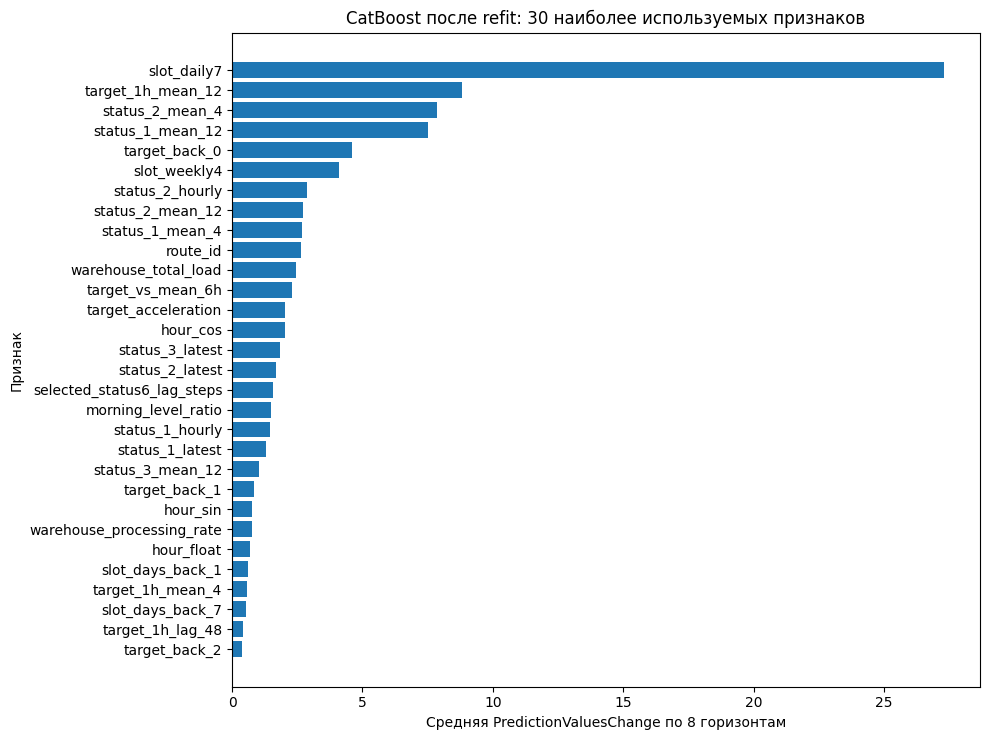

In [13]:
import matplotlib.pyplot as plt

builtin_importance = pd.concat(builtin_importance_parts, ignore_index=True)
builtin_importance.to_csv(IMPORTANCE_DIR / "catboost_importance_by_horizon.csv", index=False)
importance_summary = (builtin_importance.groupby(["stage", "feature"])["importance"]
                      .agg(["mean", "std"]).reset_index().sort_values(["stage", "mean"], ascending=[True, False]))
importance_summary.to_csv(IMPORTANCE_DIR / "catboost_importance_summary.csv", index=False)
display(importance_summary.groupby("stage", sort=False).head(30))
importance_by_horizon = builtin_importance.query("stage == 'final_model'").pivot(
    index="feature", columns="horizon", values="importance")
importance_by_horizon = importance_by_horizon.loc[importance_by_horizon.mean(axis=1).sort_values(ascending=False).index]
display(importance_by_horizon.head(30))
top = importance_summary.query("stage == 'final_model'").head(30).sort_values("mean")
fig, ax = plt.subplots(figsize=(10, max(5, len(top) * 0.25)))
ax.barh(top.feature, top["mean"])
ax.set(xlabel="Средняя PredictionValuesChange по 8 горизонтам", ylabel="Признак",
       title="CatBoost после refit: 30 наиболее используемых признаков")
fig.tight_layout()
fig.savefig(IMPORTANCE_DIR / "catboost_top30.png", dpi=150, bbox_inches="tight")
plt.show()

## Permutation importance на отложенных данных
Используются **оценочные модели до финального refit** и parquet с прежним train-словарём лагов. По умолчанию: 7 дат, равномерно выбранных из 14 отложенных, все маршруты, все 8 горизонтов, top-10 по важности оценочных моделей, два обязательных корреляционных признака и все новые группы; 3 повтора. Настройки — в первой ячейке. Нового fit нет; inference займёт дополнительное время.

Переставляются целые маршрутные траектории между маршрутами вместе с циклическим сдвигом выбранных дат. Один индекс перестановки применяется ко всем колонкам группы и всем горизонтам. Это сохраняет восемь шагов прогноза вместе и временной порядок выбранной траектории, кроме циклической границы; это специальная блочная диагностика, не iid-перестановка sklearn. Изменение признаков может создавать нетипичные сочетания, поэтому это оценка зависимости модели от входов, не причинный эффект. Групповая перестановка дополняет отдельные признаки при сильной корреляции.

Положительная `delta_mean_daily_score` означает ухудшение после перестановки и полезность признака для этой модели на выбранных датах. Считаются также изменения pooled score, WAPE и абсолютного bias в исходных единицах. `horizon=0` объединяет **все** горизонты и маршруты дня; нельзя заменить его средним score горизонтов. Смесь, калибровка и число деревьев не перенастраиваются; здесь измеряется чистый CatBoost. После просмотра этих дат отбор признаков по ним потребует новой внешней проверки.

Источники методов: [CatBoost feature importance](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_get_feature_importance), [принцип и ограничения permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

Permutation importance: feature / slot_daily7
Permutation importance: feature / target_1h_mean_12
Permutation importance: feature / status_2_mean_4
Permutation importance: feature / status_1_mean_12
Permutation importance: feature / target_back_0
Permutation importance: feature / slot_weekly4
Permutation importance: feature / status_2_hourly
Permutation importance: feature / route_id
Permutation importance: feature / lagged_status6_signal
Permutation importance: feature / selected_status6_lag_steps
Permutation importance: group / calendar
Permutation importance: group / local_statuses
Permutation importance: group / hub_combinations
Permutation importance: group / historical_lags
Permutation importance: group / target_change
Permutation importance: group / correlation_lag


,kind,name,horizon,delta_mean_daily_score_mean,delta_mean_daily_score_std,delta_pooled_score_mean,delta_pooled_score_std,delta_wape_mean,delta_wape_std,delta_abs_bias_mean,delta_abs_bias_std
27,feature,slot_daily7,0,0.045202,0.001248,0.045209,0.001265,0.031643,0.000747,0.013565,0.000635
63,feature,status_2_mean_4,0,0.023882,0.000125,0.023917,0.000125,0.013730,0.000085,0.010187,0.000060
81,feature,target_back_0,0,0.023618,0.000607,0.023064,0.000269,0.037928,0.000562,-0.014864,0.000294
72,feature,target_1h_mean_12,0,0.014966,0.000327,0.014999,0.000323,0.008453,0.000226,0.006546,0.000198
9,feature,route_id,0,0.012385,0.000157,0.012390,0.000158,0.003565,0.000165,0.008825,0.000021
126,group,local_statuses,0,0.012046,0.000111,0.012108,0.000129,0.010499,0.000187,0.001609,0.000064
36,feature,slot_weekly4,0,0.009960,0.000122,0.009970,0.000115,0.002959,0.000095,0.007011,0.000073
45,feature,status_1_mean_12,0,0.006017,0.000140,0.006050,0.000122,0.003055,0.000046,0.002994,0.000112
54,feature,status_2_hourly,0,0.005627,0.000094,0.005643,0.000094,0.002410,0.000045,0.003233,0.000073
135,group,target_change,0,0.004428,0.000087,0.004421,0.000082,0.006090,0.000105,-0.001669,0.000038


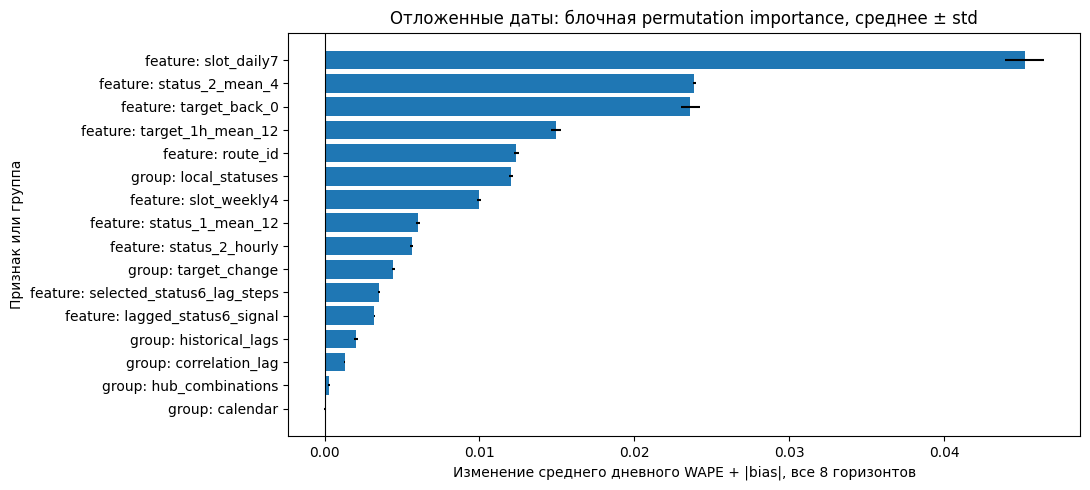

In [14]:
def block_permutation_index(frame, seed):
    """Единая биекция (дата, маршрут); горизонт не входит в перемешиваемую ось."""
    rng = np.random.default_rng(seed)
    days = pd.DatetimeIndex(frame.cutoff.unique()).sort_values()
    route_values = np.sort(frame.route_id.unique())
    keys = pd.MultiIndex.from_frame(frame[["cutoff", "route_id"]])
    if not keys.is_unique or len(frame) != len(days) * len(route_values):
        raise ValueError("Permutation importance требует полную панель дата × маршрут")
    date_shift = int(rng.integers(1, len(days))) if len(days) > 1 else 0
    donor_days = days[np.roll(np.arange(len(days)), date_shift)][days.get_indexer(frame.cutoff)]
    donor_routes = rng.permutation(route_values)[pd.Index(route_values).get_indexer(frame.route_id)]
    donor = keys.get_indexer(pd.MultiIndex.from_arrays([donor_days, donor_routes]))
    if (donor < 0).any() or len(np.unique(donor)) != len(frame):
        raise ValueError("Перестановка не является биекцией")
    return donor

def permutation_deltas(meta_parts, original_parts, shuffled_parts):
    rows = []
    for h, meta, original, shuffled in zip(range(1, 9), meta_parts, original_parts, shuffled_parts):
        before, after = score_row(meta, original, "baseline"), score_row(meta, shuffled, "permuted")
        rows.append({"horizon": h,
                     "delta_mean_daily_score": after["среднее по дням"] - before["среднее по дням"],
                     "delta_pooled_score": after["метрика конкурса"] - before["метрика конкурса"],
                     "delta_wape": after["WAPE"] - before["WAPE"],
                     "delta_abs_bias": after["|Relative Bias|"] - before["|Relative Bias|"]})
    combined = pd.concat(meta_parts, ignore_index=True)
    before = score_row(combined, np.concatenate(original_parts), "baseline")
    after = score_row(combined, np.concatenate(shuffled_parts), "permuted")
    rows.append({"horizon": 0,
                 "delta_mean_daily_score": after["среднее по дням"] - before["среднее по дням"],
                 "delta_pooled_score": after["метрика конкурса"] - before["метрика конкурса"],
                 "delta_wape": after["WAPE"] - before["WAPE"],
                 "delta_abs_bias": after["|Relative Bias|"] - before["|Relative Bias|"]})
    return rows

def run_permutation_importance():
    if PERMUTATION_MAX_DAYS < 2 or PERMUTATION_REPEATS < 2 or PERMUTATION_TOP_N < 1:
        raise ValueError("Для диагностики нужны >=2 даты, >=2 повтора и положительный top-N")
    available_days = dates[dates >= holdout_start]
    pick = np.unique(np.linspace(0, len(available_days)-1,
                                min(PERMUTATION_MAX_DAYS, len(available_days))).round().astype(int))
    selected_days = available_days[pick]
    models, matrices, metadata, original = [], [], [], []
    baseline_rows = []
    for h in range(1, 9):
        kind = model_kind_for_h(best_mode, h)
        model_key = ("residual" if kind == "residual" else kind, h)
        model_path = VALIDATION_MODEL_PATHS.get(model_key)
        if model_path is None:
            raise ValueError(f"Не найден validation-модельный файл для h={h}, kind={kind}")
        model = CatBoostRegressor()
        model.load_model(str(model_path))
        names = model.feature_names_
        meta_columns = ["cutoff", "timestamp", "route_id", "y", "profile28",
                        "slot_daily7", "slot_weekly4"]
        read_columns = list(dict.fromkeys([*meta_columns, *names]))
        frame = pd.read_parquet(OUT / f"history_h{h}.parquet", columns=read_columns,
                                filters=[("cutoff", "in", selected_days.to_pydatetime().tolist())])
        frame = frame.sort_values(["cutoff", "route_id"]).reset_index(drop=True)
        if len(frame) != len(selected_days) * len(routes):
            raise ValueError("Неполная панель отложенных данных для важностей")
        meta = frame[meta_columns].copy()
        matrix = frame[names].copy()
        prediction = model.predict(matrix) * TARGET_SCALE
        if kind == "residual":
            prediction = prediction + seasonal_baseline(meta).to_numpy(dtype=np.float64)
        prediction = np.maximum(prediction, 0)
        baseline_rows.append({"horizon": h, **score_row(meta, prediction, "permutation_baseline")})
        models.append(model)
        matrices.append(matrix)
        metadata.append(meta)
        original.append(prediction)
    combined = pd.concat(metadata, ignore_index=True)
    baseline_rows.append({"horizon": 0, **score_row(combined, np.concatenate(original), "permutation_baseline")})
    pd.DataFrame(baseline_rows).to_csv(IMPORTANCE_DIR / "permutation_baseline.csv", index=False)
    rank = (builtin_importance.loc[builtin_importance.stage.str.startswith("validation_model")]
            .groupby("feature").importance.mean().sort_values(ascending=False))
    individual = list(dict.fromkeys([*rank.head(PERMUTATION_TOP_N).index,
                                    "lagged_status6_signal", "selected_status6_lag_steps",
                                    *PILOT_H6_FEATURES]))
    specs = [("feature", name, [{name} if name in matrix.columns else set()
                                 for matrix in matrices]) for name in individual]
    specs += [("group", name, [set(columns).intersection(matrix.columns)
                                for matrix in matrices])
              for name, columns in FEATURE_GROUPS.items()]
    specs = [(kind, name, by_h) for kind, name, by_h in specs if any(by_h)]
    (IMPORTANCE_DIR / "permutation_settings.json").write_text(json.dumps({
        "days": [str(d) for d in selected_days], "routes": len(routes),
        "repeats": PERMUTATION_REPEATS, "seed": 42,
        "model_stage": f"selected_validation_model:{best_mode}",
        "lag_fit_before": str(LAG_VALIDATION_FIT_BEFORE),
        "specs": [{"kind": kind, "name": name,
                   "columns_by_horizon": [sorted(columns) for columns in by_h]}
                  for kind, name, by_h in specs],
    }, ensure_ascii=False, indent=2))
    rows = []
    for kind, name, columns_by_h in specs:
        for repeat in range(PERMUTATION_REPEATS):
            shuffled = []
            for h, model, matrix, meta, columns in zip(
                    range(1, 9), models, matrices, metadata, columns_by_h):
                if not columns:
                    shuffled.append(original[h - 1])
                    continue
                donor = block_permutation_index(meta, seed=42 + repeat)
                columns = sorted(columns)
                permuted = matrix.copy()
                permuted.loc[:, columns] = matrix.iloc[donor][columns].to_numpy()
                prediction = model.predict(permuted) * TARGET_SCALE
                if model_kind_for_h(best_mode, h) == "residual":
                    prediction = prediction + seasonal_baseline(meta).to_numpy(dtype=np.float64)
                shuffled.append(np.maximum(prediction, 0))
            for row in permutation_deltas(metadata, original, shuffled):
                rows.append({"kind": kind, "name": name, "repeat": repeat,
                             "n_features": sum(len(columns) for columns in columns_by_h), **row})
        print(f"Permutation importance: {kind} / {name}")
    detail = pd.DataFrame(rows)
    detail.to_csv(IMPORTANCE_DIR / "permutation_detail.csv", index=False)
    metrics = ["delta_mean_daily_score", "delta_pooled_score", "delta_wape", "delta_abs_bias"]
    summary = detail.groupby(["kind", "name", "horizon"])[metrics].agg(["mean", "std"])
    summary.columns = ["_".join(column) for column in summary.columns]
    summary = summary.reset_index().sort_values("delta_mean_daily_score_mean", ascending=False)
    summary.to_csv(IMPORTANCE_DIR / "permutation_summary.csv", index=False)
    return summary

if PERMUTATION_ENABLED:
    permutation_summary = run_permutation_importance()
    overall = permutation_summary.loc[permutation_summary.horizon.eq(0)].copy()
    display(overall)
    plot = overall.sort_values("delta_mean_daily_score_mean")
    fig, ax = plt.subplots(figsize=(11, max(5, len(plot) * 0.3)))
    ax.barh(plot.kind + ": " + plot.name, plot.delta_mean_daily_score_mean,
            xerr=plot.delta_mean_daily_score_std.fillna(0))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(xlabel="Изменение среднего дневного WAPE + |bias|, все 8 горизонтов",
           ylabel="Признак или группа", title="Отложенные даты: блочная permutation importance, среднее ± std")
    fig.tight_layout()
    fig.savefig(IMPORTANCE_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Permutation importance отключена настройкой PERMUTATION_ENABLED; важности CatBoost показаны выше.")